In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/ADNIMERGE2/research_dataset/clean_cn_amyloid_dataset.csv"
)

In [3]:
df.head()

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT
0,6001,0,0.386,0.0973,27.5,175.4,0,73.051335,0,14.0
1,6005,0,0.105,0.0843,9.8,181.3,1,68.334018,0,20.0
2,6015,0,1.291,0.0839,34.4,304.4,0,68.396988,1,14.0
3,6009,0,0.111,0.0857,12.2,100.8,1,68.369610,1,16.0
4,6044,1,0.627,0.0885,26.5,209.3,1,75.526352,0,18.0


In [4]:
# Cell 1: Structural & Duplicate Audit
print("--- Dataset Dimensions ---")
print(f"Total Subjects: {df.shape[0]}")
print(f"Total Features: {df.shape[1]}\n")

print("--- Data Type Distribution ---")
print(df.dtypes.value_counts())

print("\n--- Duplicate Row Check ---")
duplicate_count = df.duplicated().sum()
print(f"Identical duplicate rows detected: {duplicate_count}")
if duplicate_count > 0:
    print("Warning: Duplicate rows must be dropped before splitting data.")

--- Dataset Dimensions ---
Total Subjects: 238
Total Features: 10

--- Data Type Distribution ---
float64    6
int64      4
Name: count, dtype: int64

--- Duplicate Row Check ---
Identical duplicate rows detected: 0


In [5]:
# Cell 4: Distribution Skewness & Variance Audit
import numpy as np
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Remove the target column if it's already numeric (e.g., 0 or 1)
# Replace 'target' with your exact target column name if needed
if 'target' in numeric_cols:
    numeric_cols.remove('target')

print("--- Low Variance Audit (Constants) ---")
variances = df[numeric_cols].var()
low_variance_cols = variances[variances < 1e-4].index.tolist()
print(f"Features with near-zero variance: {low_variance_cols}")

print("\n--- Highly Skewed Biomarkers (|Skew| > 1.5) ---")
skewness = df[numeric_cols].skew()
highly_skewed_cols = skewness[abs(skewness) > 1.5].index.tolist()

for col in highly_skewed_cols:
    print(f"{col:<25} | Skewness Score: {df[col].skew():.2f}")

--- Low Variance Audit (Constants) ---
Features with near-zero variance: []

--- Highly Skewed Biomarkers (|Skew| > 1.5) ---
pT217_F                   | Skewness Score: 5.49


In [7]:
pip install ydata-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 85.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.7/679.7 kB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 5.8 MB/s eta 0:00:00


In [8]:
import pandas as pd
from ydata_profiling import ProfileReport

# 1. Load your dataset (Replace 'your_data.csv' with your actual file path)
# You can also use a public URL or any valid pandas DataFrame

# 2. Generate the profiling report
# Setting explorative=True uncovers deeper insights like text/image specific metrics
profile = ProfileReport(df, title="My Data Profiling Report", explorative=True)

# 3. Export the report to an HTML file
profile.to_file("data_analysis_report.html")

print("Report generated successfully as 'data_analysis_report.html'!")


/tmp/ipykernel_1277/1029240645.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 10/10 [00:00<00:00, 168.78it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Report generated successfully as 'data_analysis_report.html'!


In [9]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [10]:
X = df.iloc[:,2:]
y = df.iloc[:,1]

In [11]:
X

,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT
0,0.386,0.0973,27.5,175.4,0,73.051335,0,14.0
1,0.105,0.0843,9.8,181.3,1,68.334018,0,20.0
2,1.291,0.0839,34.4,304.4,0,68.396988,1,14.0
3,0.111,0.0857,12.2,100.8,1,68.369610,1,16.0
4,0.627,0.0885,26.5,209.3,1,75.526352,0,18.0
...,...,...,...,...,...,...,...,...
233,0.079,0.1026,12.7,141.1,1,63.764545,0,16.0
234,0.159,0.0812,13.4,202.4,1,66.171116,0,16.0
235,0.033,0.0980,10.1,80.4,1,65.886379,0,17.0
236,0.385,0.0816,20.8,249.3,1,81.374401,0,14.0


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

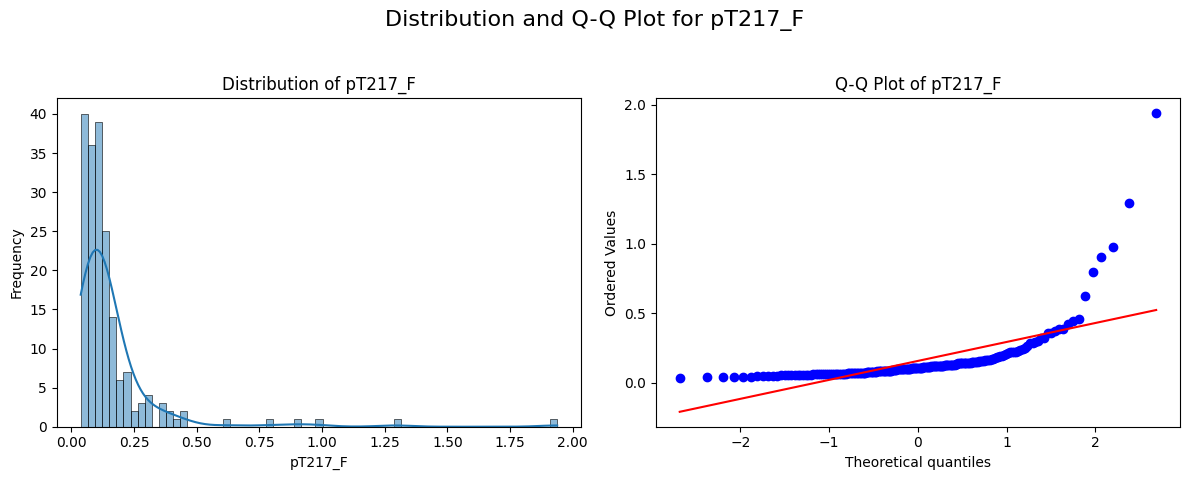

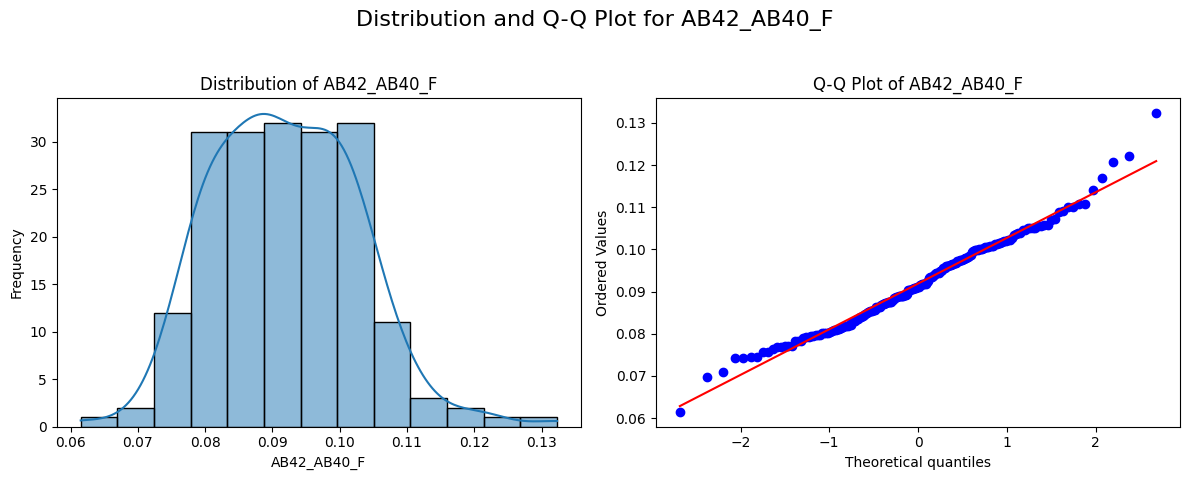

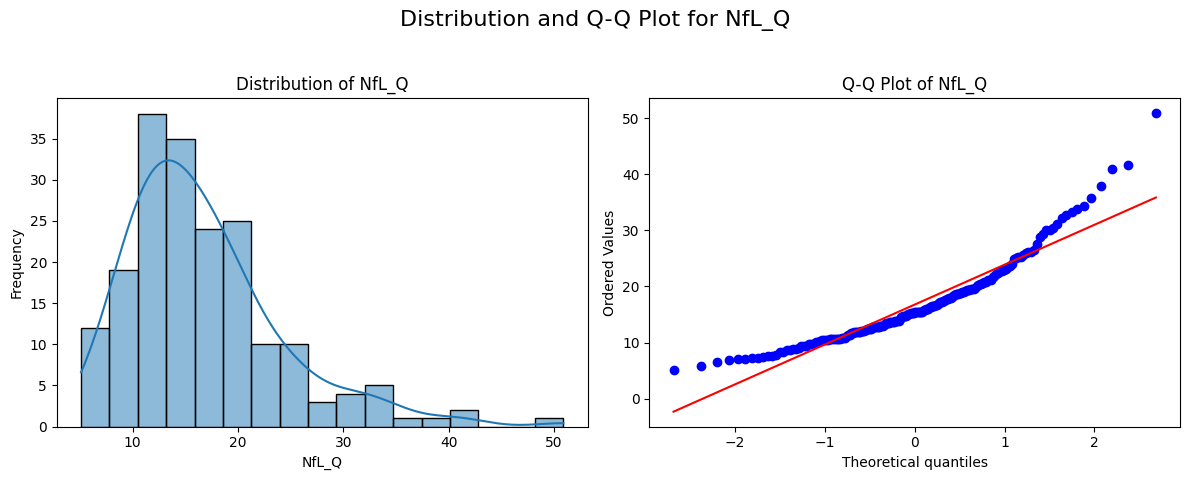

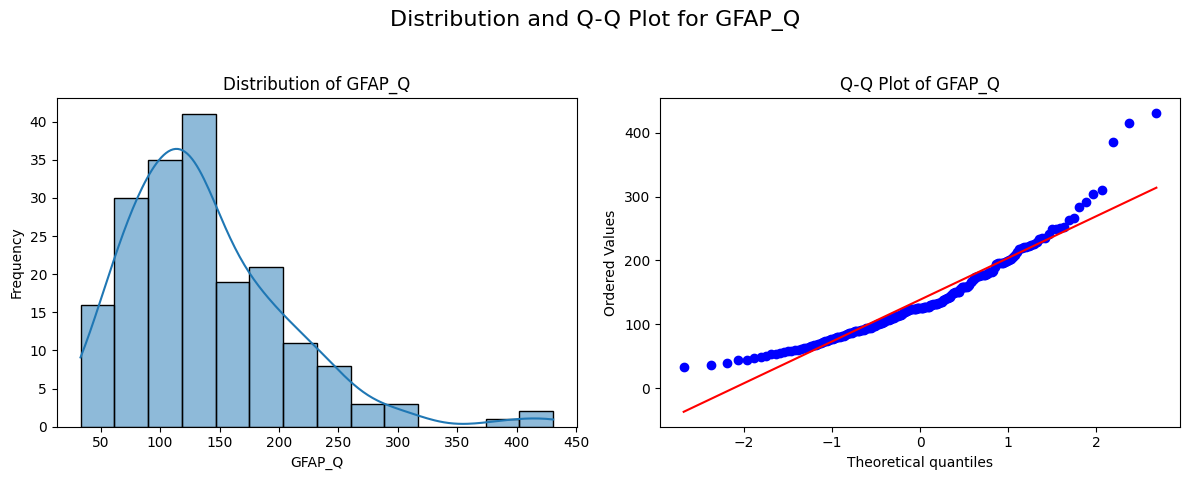

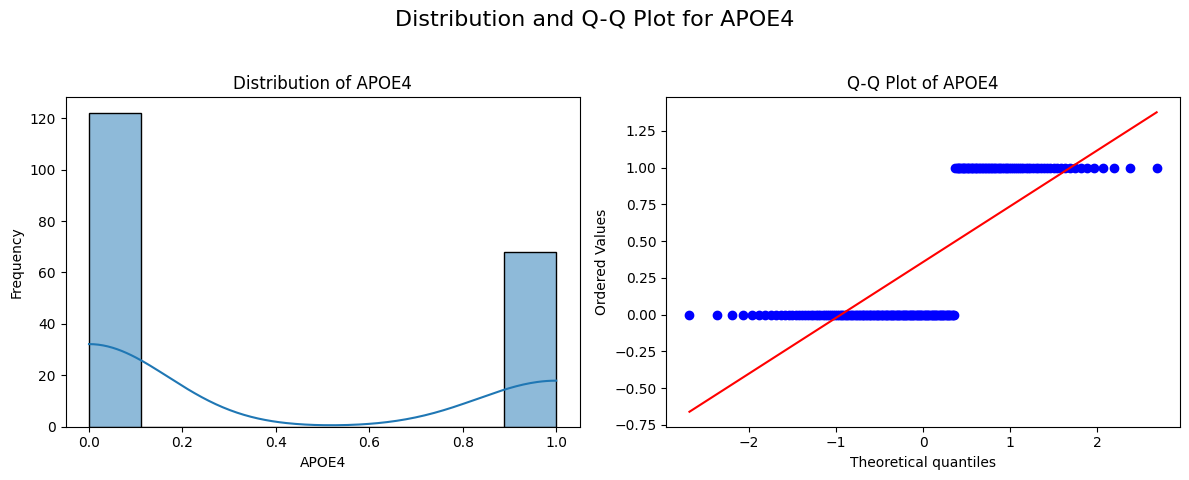

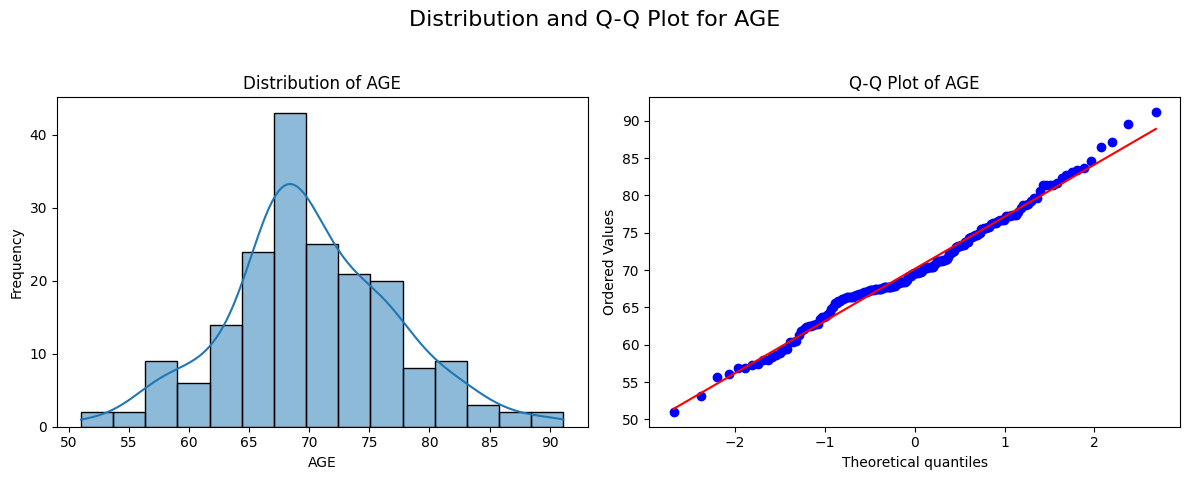

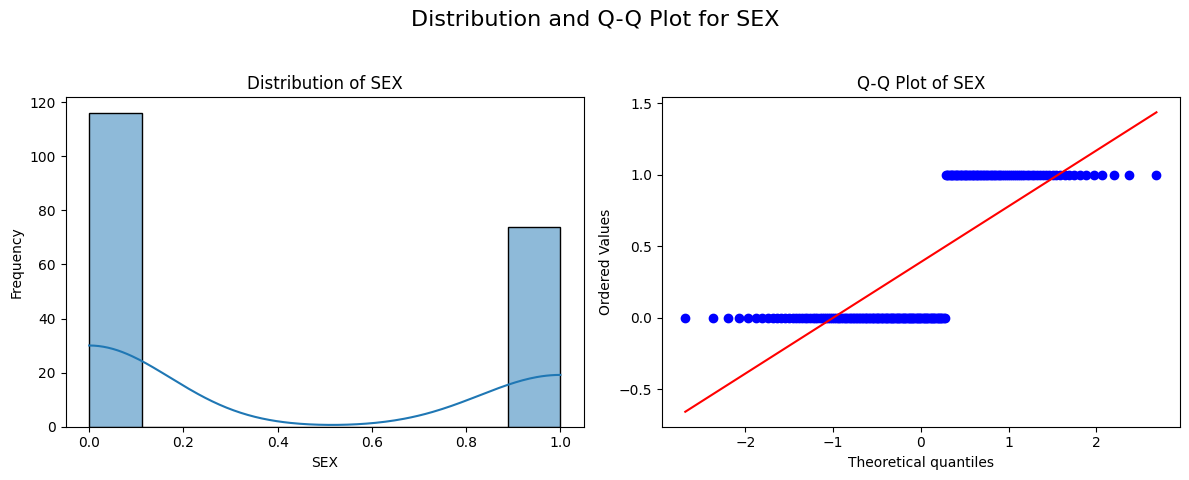

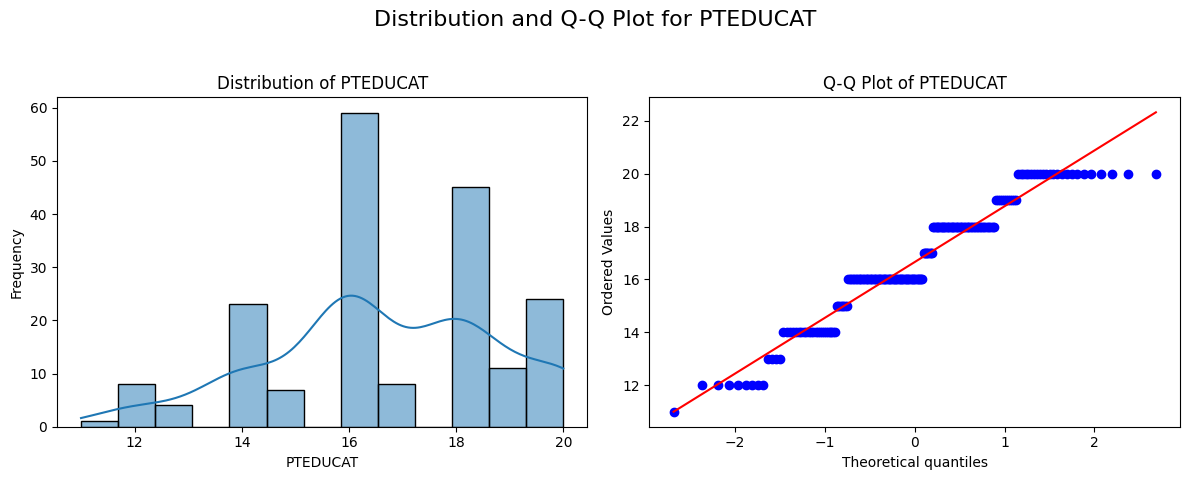

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

for col in X_train.columns:
    # Create a figure with two subplots
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f'Distribution and Q-Q Plot for {col}', fontsize=16)

    # Distplot
    sns.histplot(X_train[col], kde=True, ax=axes[0])
    axes[0].set_title(f'Distribution of {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequency')

    # Q-Q Plot
    stats.probplot(X_train[col], dist="norm", plot=axes[1])
    axes[1].set_title(f'Q-Q Plot of {col}')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
    plt.show()

<Axes: ylabel='pT217_F'>

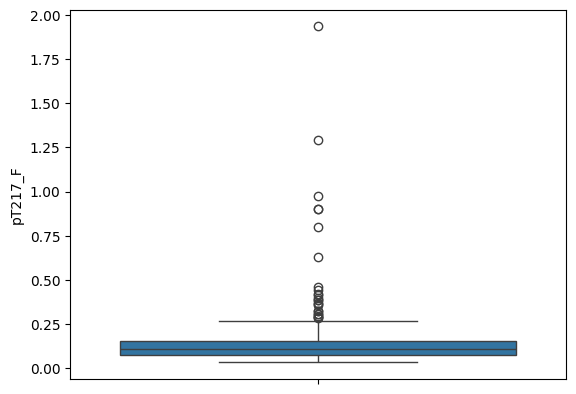

In [14]:
sns.boxplot(df['pT217_F'])

In [15]:
df['pT217_F'].describe()

,pT217_F
count,238.000000
mean,0.153420
std,0.191283
min,0.030000
25%,0.071250
50%,0.104500
75%,0.152500
max,1.938000


In [16]:
percentile25 = df['pT217_F'].quantile(0.25)
percentile75 = df['pT217_F'].quantile(0.75)
iqr = percentile75 - percentile25

In [17]:
upper_limit = percentile75 + 1.5 * iqr
lower_limit = percentile25 - 1.5 * iqr

In [18]:
print("Upper Limit:", upper_limit)
print("Lower Limit:", lower_limit)

Upper Limit: 0.27437500000000004
Lower Limit: -0.05062500000000002


In [20]:
df[df['pT217_F'] > upper_limit]

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT
0,6001,0,0.386,0.0973,27.5,175.4,0,73.051335,0,14.0
2,6015,0,1.291,0.0839,34.4,304.4,0,68.396988,1,14.0
4,6044,1,0.627,0.0885,26.5,209.3,1,75.526352,0,18.0
11,6061,1,0.441,0.0829,18.3,195.6,0,74.735113,0,16.0
21,6084,1,0.975,0.0910,33.8,220.4,0,78.866530,1,20.0
24,6065,1,0.395,0.0755,50.6,289.9,1,71.876797,0,18.0
26,6186,1,0.360,0.0875,38.0,225.2,0,91.137577,1,12.0
42,6199,1,0.901,0.0835,23.0,223.9,1,70.236824,1,16.0
47,6173,1,0.358,0.0821,25.0,292.4,0,71.252567,0,16.0
49,6255,1,0.456,0.0818,22.7,386.1,1,76.251882,0,13.0


In [21]:
df[df['pT217_F'] < lower_limit]

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT


In [22]:
new_df = df.copy()

In [23]:
import numpy as np
new_df['pT217_F'] = np.where(new_df['pT217_F'] > upper_limit,
                             upper_limit,
                             np.where(new_df['pT217_F'] < lower_limit, lower_limit, new_df['pT217_F']))

<Axes: ylabel='pT217_F'>

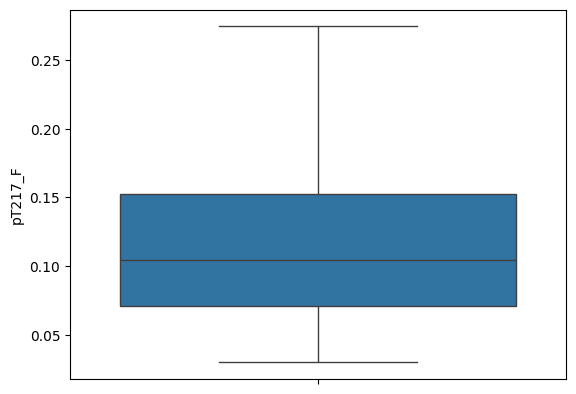

In [24]:
sns.boxplot(new_df['pT217_F'])